# Weather Pattern Analysis and Classification Using Unsupervised Clustering Algorithms
**Subject:** Unsupervised Learning Algorithms | **Programme:** B.Tech Artificial Intelligence and Data Science

This notebook discovers natural weather groups in real daily weather observations using three **unsupervised** algorithms:
**K-Means**, **Agglomerative Hierarchical Clustering** and **DBSCAN**. No labels are used for training and no supervised model is used.

**How to run (Google Colab):** open this file in Colab → *Runtime → Run all*. The dataset is downloaded automatically from GitHub. No upload and no `pip install` is needed (pandas, numpy, matplotlib, seaborn, scikit-learn and scipy are pre-installed in Colab).
**How to run (local Jupyter):** `pip install pandas numpy matplotlib seaborn scikit-learn scipy jupyter`, then run all cells.

## Dataset and source
* **Name:** Rain in Australia / weatherAUS (daily weather observations from many Australian weather stations).
* **Original data owner:** Australian Bureau of Meteorology (BoM) – http://www.bom.gov.au/climate/data
* **Kaggle page (original compilation):** https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package
* **Direct download used by this notebook (public GitHub mirror, no login):** https://raw.githubusercontent.com/tvdboom/ATOM/master/examples/datasets/weatherAUS.csv

The BoM data are used here for educational purposes with acknowledgement of the Bureau of Meteorology as the source.
> Note: this GitHub copy has no `Date` column, and its `RainTomorrow` column is stored as 0/1. We do **not** use `RainToday` or `RainTomorrow` for clustering.

## Column explanation
| Column | Meaning | Unit |
|---|---|---|
| Location | Weather station name | text |
| MinTemp / MaxTemp | Minimum / maximum temperature of the day | °C |
| Rainfall | Rain recorded in the 24 hours to 9am | mm |
| Evaporation | Class-A pan evaporation in the 24 hours to 9am | mm |
| Sunshine | Hours of bright sunshine in the day | hours |
| WindGustDir / WindGustSpeed | Direction / speed of the strongest wind gust | compass / km/h |
| WindDir9am, WindDir3pm | Wind direction at 9am / 3pm | compass |
| WindSpeed9am, WindSpeed3pm | Average wind speed over 10 minutes before 9am / 3pm | km/h |
| Humidity9am, Humidity3pm | Relative humidity at 9am / 3pm | % |
| Pressure9am, Pressure3pm | Atmospheric pressure reduced to mean sea level | hPa |
| Cloud9am, Cloud3pm | Sky covered by cloud (0 = clear, 8 = overcast) | oktas |
| Temp9am, Temp3pm | Temperature at 9am / 3pm | °C |
| RainToday | Did it rain today (>1 mm)? | Yes/No |
| RainTomorrow | Did it rain the next day? (0/1 in this copy) | 0/1 |

**Features chosen for clustering (6):** `MinTemp`, `MaxTemp` (temperature), `Rainfall`, `Humidity3pm`, `WindSpeed3pm`, `Pressure3pm`. These cover temperature, humidity, rainfall, wind speed and pressure, which are the main weather elements.

## 1. Import libraries and settings

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA              # only used to draw 2-D pictures
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42           # makes results repeatable
SAMPLE_SIZE = 5000          # rows used for clustering (hierarchical clustering needs O(n^2) memory)
GRAPH_DIR = "output_graphs"
os.makedirs(GRAPH_DIR, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(GRAPH_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the dataset automatically from GitHub

In [2]:
DATA_URL = "https://raw.githubusercontent.com/tvdboom/ATOM/master/examples/datasets/weatherAUS.csv"
df_raw = pd.read_csv(DATA_URL)          # downloads directly - no manual upload needed
print("Raw dataset shape (rows, columns):", df_raw.shape)
df_raw.head()

Raw dataset shape (rows, columns): (142193, 22)


,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,MelbourneAirport,18.0,26.9,21.4,7.0,8.9,SSE,41.0,W,SSE,...,95.0,54.0,1019.5,1017.0,8.0,5.0,18.5,26.0,Yes,0
1,Adelaide,17.2,23.4,0.0,NaN,NaN,S,41.0,S,WSW,...,59.0,36.0,1015.7,1015.7,NaN,NaN,17.7,21.9,No,0
2,Cairns,18.6,24.6,7.4,3.0,6.1,SSE,54.0,SSE,SE,...,78.0,57.0,1018.7,1016.6,3.0,3.0,20.8,24.1,Yes,0
3,Portland,13.6,16.8,4.2,1.2,0.0,ESE,39.0,ESE,ESE,...,76.0,74.0,1021.4,1020.5,7.0,8.0,15.6,16.0,Yes,1
4,Walpole,16.4,19.9,0.0,NaN,NaN,SE,44.0,SE,SE,...,78.0,70.0,1019.4,1018.9,NaN,NaN,17.4,18.1,No,0


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 142193 entries, 0 to 142192
Data columns (total 22 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Location       142193 non-null  str    
 1   MinTemp        141556 non-null  float64
 2   MaxTemp        141871 non-null  float64
 3   Rainfall       140787 non-null  float64
 4   Evaporation    81350 non-null   float64
 5   Sunshine       74377 non-null   float64
 6   WindGustDir    132863 non-null  str    
 7   WindGustSpeed  132923 non-null  float64
 8   WindDir9am     132180 non-null  str    
 9   WindDir3pm     138415 non-null  str    
 10  WindSpeed9am   140845 non-null  float64
 11  WindSpeed3pm   139563 non-null  float64
 12  Humidity9am    140419 non-null  float64
 13  Humidity3pm    138583 non-null  float64
 14  Pressure9am    128179 non-null  float64
 15  Pressure3pm    128212 non-null  float64
 16  Cloud9am       88536 non-null   float64
 17  Cloud3pm       85099 non-null   float64


## 3. Data cleaning
Steps: (1) remove duplicate rows, (2) inspect missing values, (3) select the numerical weather features, (4) drop rows with missing values in those features.
Rows with missing values are **dropped** (instead of filled) so that no invented numbers enter the data. Several stations do not record pressure at all, so some stations lose rows; this is a limitation noted in the report.

In [4]:
n_raw = len(df_raw)
n_dup = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {n_dup}")

missing = df.isnull().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
print("\nMissing values per column:")
display(missing.sort_values("missing_count", ascending=False))

Duplicate rows removed: 45

Missing values per column:


,missing_count,missing_percent
Sunshine,67771,47.68
Evaporation,60798,42.77
Cloud3pm,57049,40.13
Cloud9am,53612,37.72
Pressure9am,13969,9.83
Pressure3pm,13936,9.80
WindDir9am,9968,7.01
WindGustDir,9285,6.53
WindGustSpeed,9225,6.49
WindDir3pm,3733,2.63


In [5]:
FEATURES = ["MinTemp", "MaxTemp", "Rainfall", "Humidity3pm", "WindSpeed3pm", "Pressure3pm"]
df_feat = df[FEATURES].copy()
missing_feat = df_feat.isnull().sum()
print("Missing values in the selected features:\n", missing_feat)

n_before_na = len(df_feat)
df_clean = df_feat.dropna().reset_index(drop=True)
print(f"\nRows before dropping missing: {n_before_na}")
print(f"Rows after dropping missing : {len(df_clean)}  (removed {n_before_na-len(df_clean)})")
print("Remaining missing values:", int(df_clean.isnull().sum().sum()))

Missing values in the selected features:
 MinTemp           592
MaxTemp           283
Rainfall         1403
Humidity3pm      3565
WindSpeed3pm     2585
Pressure3pm     13936
dtype: int64

Rows before dropping missing: 142148
Rows after dropping missing : 124426  (removed 17722)
Remaining missing values: 0


## 4. Exploratory data analysis and statistical summary

In [6]:
summary = df_clean.describe().T
summary["skewness"] = df_clean.skew()
display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness
MinTemp,124426.0,12.40,6.33,-8.2,7.8,12.2,17.00,33.9,0.05
MaxTemp,124426.0,23.41,6.94,2.6,18.0,22.8,28.40,48.1,0.34
Rainfall,124426.0,2.34,8.50,0.0,0.0,0.0,0.68,371.0,10.07
Humidity3pm,124426.0,51.22,20.66,0.0,36.0,52.0,65.00,100.0,-0.00
WindSpeed3pm,124426.0,19.08,8.71,0.0,13.0,19.0,24.00,87.0,0.64
Pressure3pm,124426.0,1015.28,7.03,977.1,1010.5,1015.3,1020.00,1039.6,-0.06


**Distributions** of temperature, humidity and rainfall. Rainfall is strongly right-skewed (most days have little or no rain), so we also show a log-transformed version.

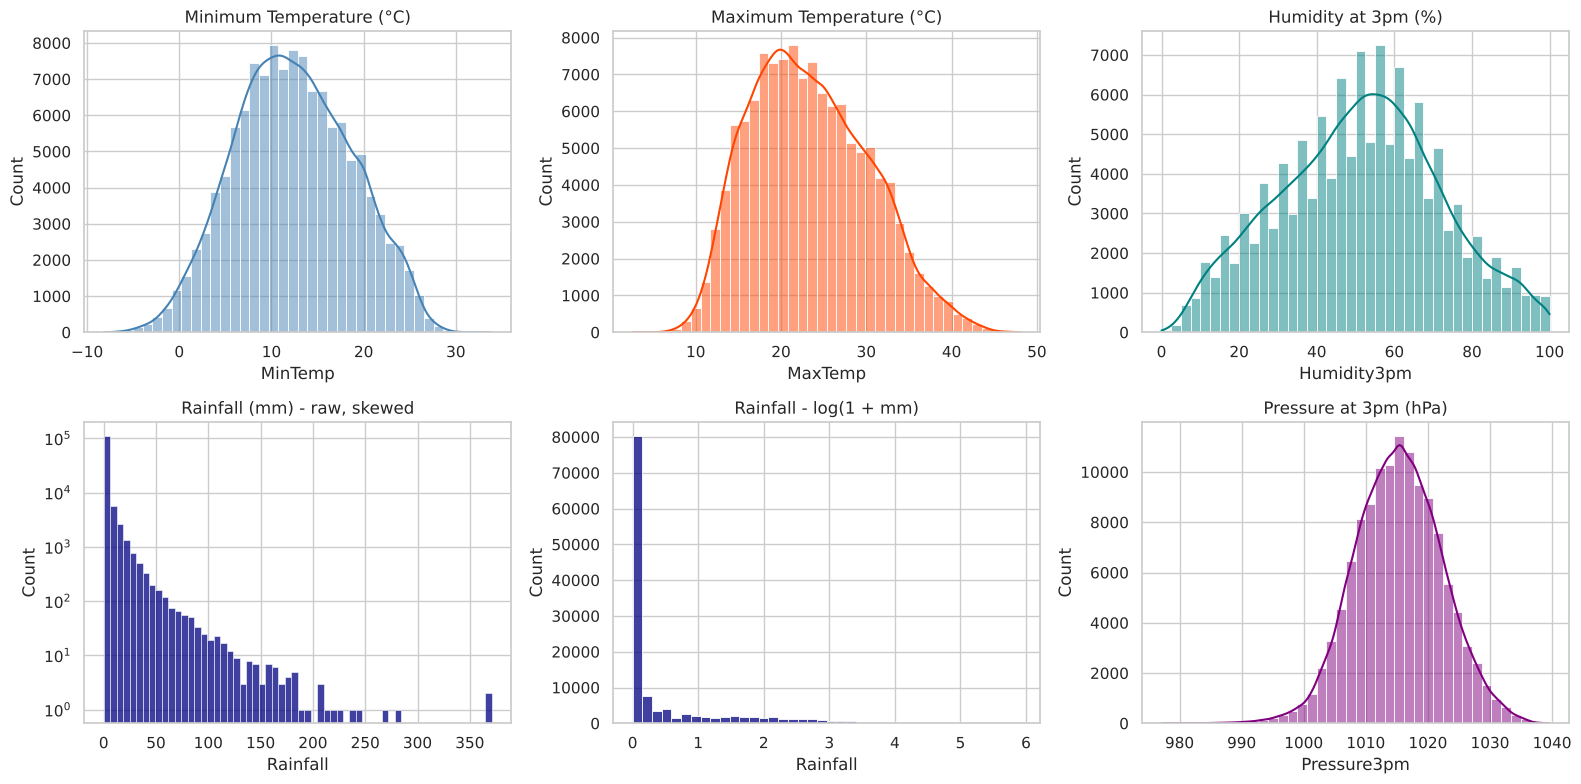

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(df_clean["MinTemp"], bins=40, kde=True, ax=ax[0,0], color="steelblue").set_title("Minimum Temperature (°C)")
sns.histplot(df_clean["MaxTemp"], bins=40, kde=True, ax=ax[0,1], color="orangered").set_title("Maximum Temperature (°C)")
sns.histplot(df_clean["Humidity3pm"], bins=40, kde=True, ax=ax[0,2], color="teal").set_title("Humidity at 3pm (%)")
sns.histplot(df_clean["Rainfall"], bins=60, ax=ax[1,0], color="navy").set_title("Rainfall (mm) - raw, skewed")
ax[1,0].set_yscale("log")
sns.histplot(np.log1p(df_clean["Rainfall"]), bins=40, ax=ax[1,1], color="navy").set_title("Rainfall - log(1 + mm)")
sns.histplot(df_clean["Pressure3pm"], bins=40, kde=True, ax=ax[1,2], color="purple").set_title("Pressure at 3pm (hPa)")
save_fig("01_distributions.png")

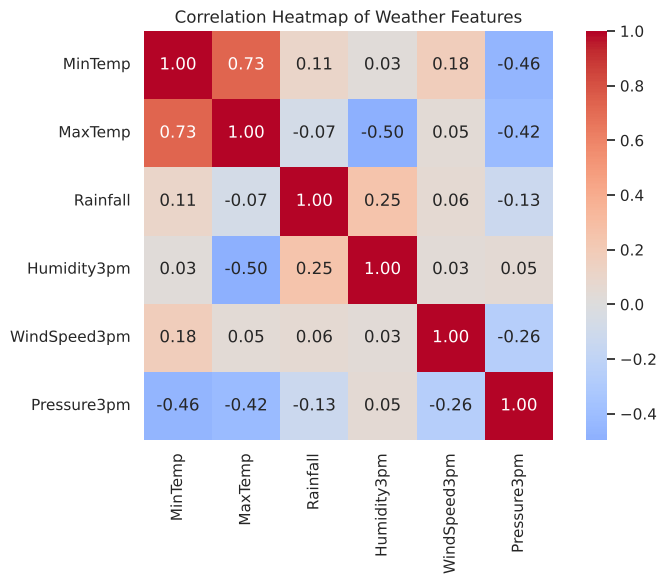

In [8]:
plt.figure(figsize=(8, 6))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap of Weather Features")
save_fig("02_correlation_heatmap.png")

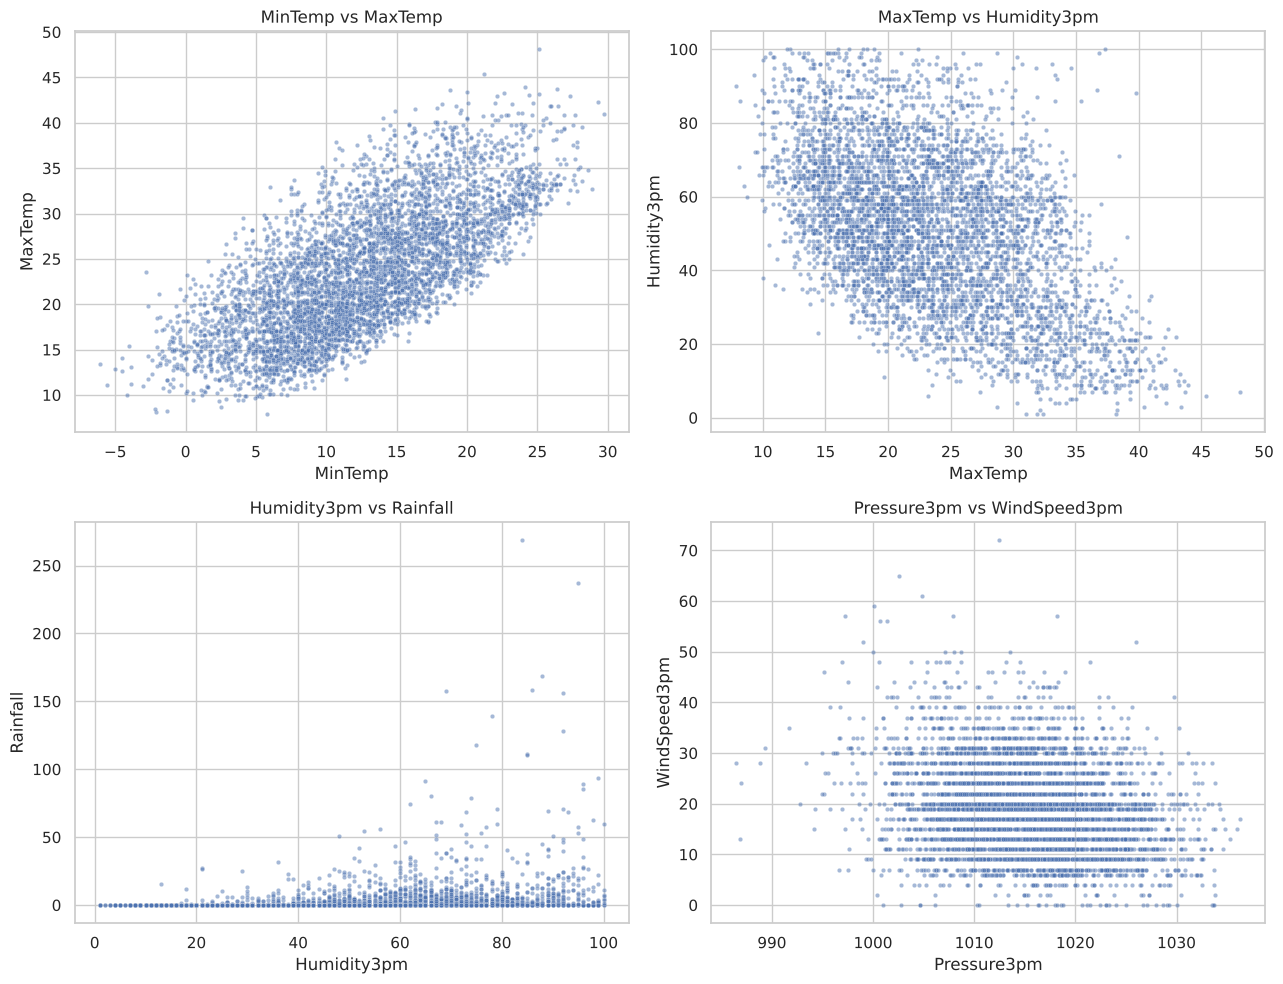

In [9]:
eda = df_clean.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
sns.scatterplot(data=eda, x="MinTemp", y="MaxTemp", s=10, alpha=0.5, ax=ax[0,0]).set_title("MinTemp vs MaxTemp")
sns.scatterplot(data=eda, x="MaxTemp", y="Humidity3pm", s=10, alpha=0.5, ax=ax[0,1]).set_title("MaxTemp vs Humidity3pm")
sns.scatterplot(data=eda, x="Humidity3pm", y="Rainfall", s=10, alpha=0.5, ax=ax[1,0]).set_title("Humidity3pm vs Rainfall")
sns.scatterplot(data=eda, x="Pressure3pm", y="WindSpeed3pm", s=10, alpha=0.5, ax=ax[1,1]).set_title("Pressure3pm vs WindSpeed3pm")
save_fig("03_scatter_plots.png")

## 5. Pre-processing: log transform, scaling, sampling
* `Rainfall` is log-transformed with `log(1 + x)` to reduce its heavy skew (otherwise a few storm days dominate distances).
* **StandardScaler** gives every feature mean 0 and standard deviation 1, because K-Means, Hierarchical and DBSCAN all use distances.
* A random sample of **5,000 days** (same sample for all three algorithms, so the comparison is fair) is used for clustering. Hierarchical clustering stores all pairwise distances, which is too large for 100,000+ rows.

In [10]:
X_model = df_clean.copy()
X_model["Rainfall"] = np.log1p(X_model["Rainfall"])
X_model = X_model.rename(columns={"Rainfall": "Rainfall_log"})

scaler = StandardScaler()
X_scaled_all = scaler.fit_transform(X_model)

rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(df_clean), size=SAMPLE_SIZE, replace=False)
X = X_scaled_all[idx]                         # data given to the algorithms
sample_orig = df_clean.iloc[idx].reset_index(drop=True)   # same rows, original units (for interpretation)
print("Clustering matrix shape:", X.shape)
print("Mean ~ 0 :", np.round(X.mean(axis=0), 2))
print("Std  ~ 1 :", np.round(X.std(axis=0), 2))

# PCA is used ONLY to draw the clusters in 2-D (not for clustering)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("PCA variance explained by 2 components:", np.round(pca.explained_variance_ratio_, 3), "->", round(pca.explained_variance_ratio_.sum()*100,1), "%")

def plot_clusters(labels, title, fname):
    """Draw clusters in PCA space and in MaxTemp-vs-Humidity space. Label -1 (DBSCAN noise) is drawn in black."""
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    uniq = sorted(set(labels))
    pal = sns.color_palette("tab10", n_colors=max(len(uniq), 3))
    for i, c in enumerate(uniq):
        m = labels == c
        col, name, mk = ("black", f"Noise ({m.sum()})", "x") if c == -1 else (pal[i % 10], f"Cluster {c} ({m.sum()})", "o")
        ax[0].scatter(X_pca[m,0], X_pca[m,1], s=12 if c!=-1 else 18, c=[col], label=name, alpha=0.6, marker=mk)
        ax[1].scatter(sample_orig["MaxTemp"][m], sample_orig["Humidity3pm"][m], s=12 if c!=-1 else 18, c=[col], alpha=0.6, marker=mk)
    ax[0].set_title(title + " - PCA view"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=8)
    ax[1].set_title(title + " - MaxTemp vs Humidity3pm"); ax[1].set_xlabel("MaxTemp (°C)"); ax[1].set_ylabel("Humidity3pm (%)")
    save_fig(fname)

Clustering matrix shape: (5000, 6)
Mean ~ 0 : [ 0.01  0.02  0.   -0.01 -0.01 -0.01]
Std  ~ 1 : [0.98 0.99 1.01 1.01 1.   0.99]
PCA variance explained by 2 components: [0.362 0.268] -> 63.1 %


## 6. Algorithm 1 – K-Means
K-Means needs the number of clusters *k* in advance. We try k = 2 … 10 and look at:
* **Elbow method:** inertia (within-cluster sum of squares) – the bend ("elbow") shows where extra clusters stop helping much.
* **Silhouette score** (higher is better) and **Davies-Bouldin index** (lower is better).

To obtain more than a simple "two-group" split, the final *k* is the value in 3…8 with the highest silhouette score.

,k,inertia,silhouette,davies_bouldin
0,2,22501.2617,0.2296,1.6305
1,3,18168.5572,0.2486,1.3553
2,4,16036.9780,0.2183,1.5158
3,5,14647.6535,0.2126,1.4595
4,6,13470.9698,0.1849,1.4374
5,7,12666.4826,0.1823,1.4489
6,8,11943.7427,0.1827,1.4410
7,9,11396.0599,0.1806,1.4418
8,10,10902.5956,0.1676,1.4549


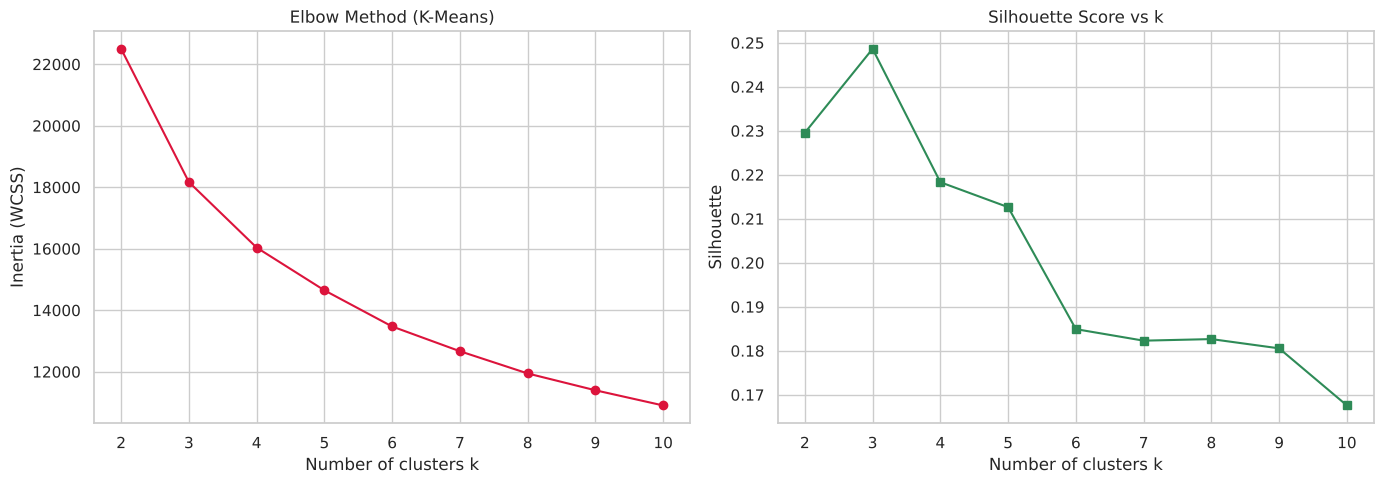

Selected k for K-Means: 3


In [11]:
k_range = range(2, 11)
km_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    km_rows.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X, km.labels_),
                    "davies_bouldin": davies_bouldin_score(X, km.labels_)})
km_table = pd.DataFrame(km_rows)
display(km_table.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(km_table["k"], km_table["inertia"], "o-", color="crimson")
ax[0].set_title("Elbow Method (K-Means)"); ax[0].set_xlabel("Number of clusters k"); ax[0].set_ylabel("Inertia (WCSS)")
ax[1].plot(km_table["k"], km_table["silhouette"], "s-", color="seagreen")
ax[1].set_title("Silhouette Score vs k"); ax[1].set_xlabel("Number of clusters k"); ax[1].set_ylabel("Silhouette")
save_fig("04_kmeans_elbow.png")

cand = km_table[(km_table.k >= 3) & (km_table.k <= 8)]
best_k = int(cand.loc[cand["silhouette"].idxmax(), "k"])
print("Selected k for K-Means:", best_k)

K-Means cluster sizes: {0: np.int64(820), 1: np.int64(2002), 2: np.int64(2178)}


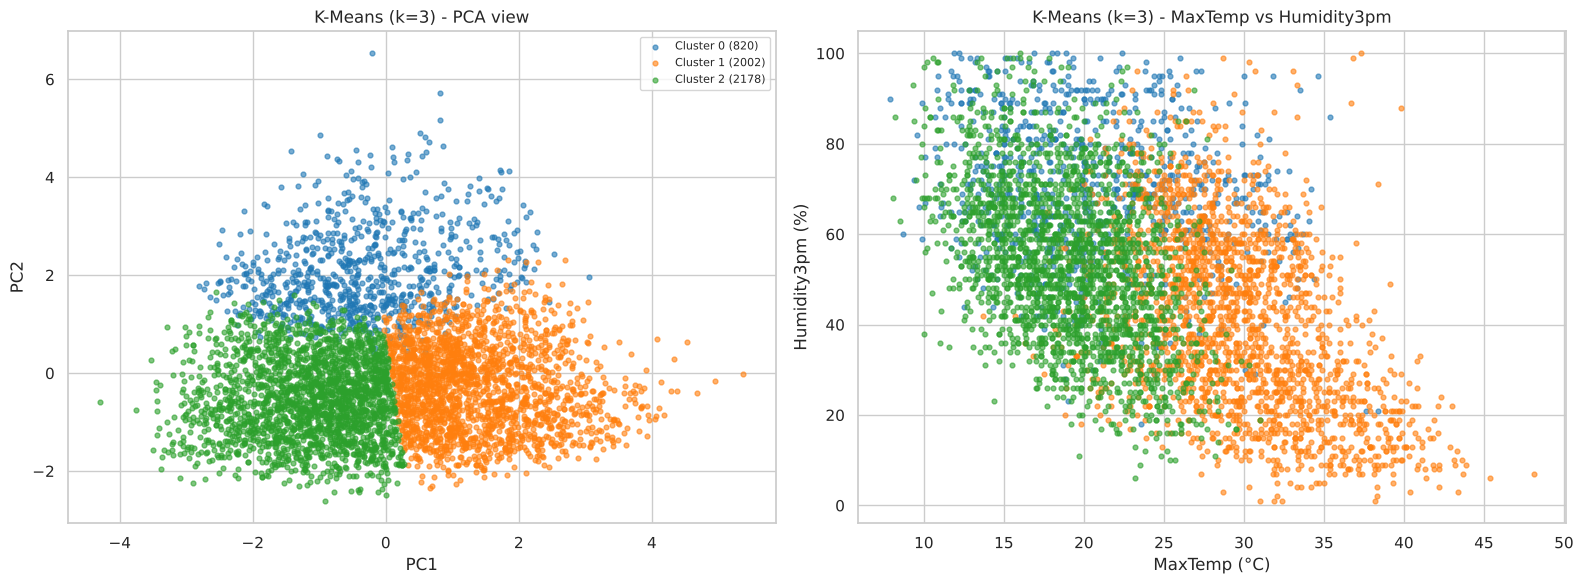

In [12]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_
print("K-Means cluster sizes:", dict(pd.Series(km_labels).value_counts().sort_index()))
plot_clusters(km_labels, f"K-Means (k={best_k})", "05_kmeans_clusters.png")

## 7. Algorithm 2 – Agglomerative Hierarchical Clustering
It starts with every day as its own cluster and repeatedly merges the two closest clusters (**Ward linkage**: merge the pair that increases variance the least). The **dendrogram** shows the merge history; cutting it at a height gives the clusters.

,k,silhouette,davies_bouldin
0,2,0.1707,1.8934
1,3,0.1919,1.5797
2,4,0.1602,1.6137
3,5,0.1119,1.7497
4,6,0.1155,1.7338
5,7,0.1086,1.7360
6,8,0.1048,1.6736
7,9,0.1087,1.6498
8,10,0.0868,1.6390


Selected number of clusters for Hierarchical: 3


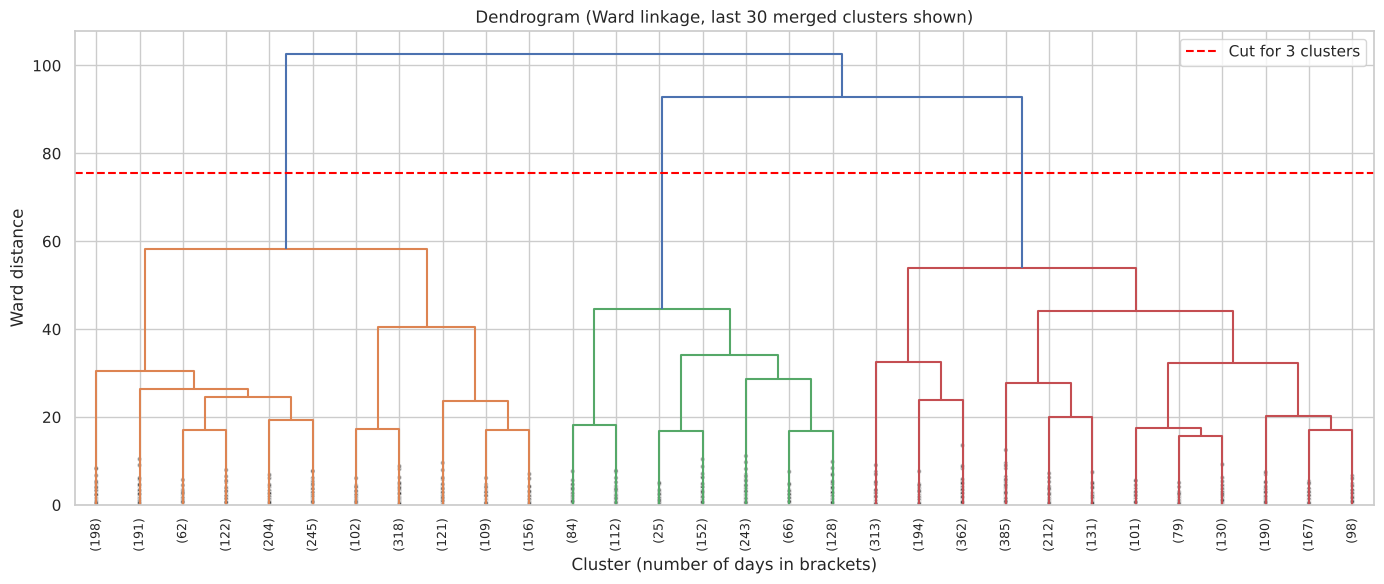

In [13]:
Z = linkage(X, method="ward")        # full merge history, used for the dendrogram

hc_rows = []
for k in range(2, 11):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    hc_rows.append({"k": k, "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab)})
hc_table = pd.DataFrame(hc_rows)
display(hc_table.round(4))
cand = hc_table[(hc_table.k >= 3) & (hc_table.k <= 8)]
best_hc_k = int(cand.loc[cand["silhouette"].idxmax(), "k"])
print("Selected number of clusters for Hierarchical:", best_hc_k)

# cut height that gives best_hc_k clusters = distance of the (n-k)-th merge
cut_height = (Z[-(best_hc_k-1), 2] + Z[-best_hc_k, 2]) / 2
plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True, color_threshold=cut_height)
plt.axhline(cut_height, color="red", linestyle="--", label=f"Cut for {best_hc_k} clusters")
plt.title("Dendrogram (Ward linkage, last 30 merged clusters shown)")
plt.xlabel("Cluster (number of days in brackets)"); plt.ylabel("Ward distance"); plt.legend()
save_fig("06_dendrogram.png")

Hierarchical cluster sizes: {0: np.int64(1828), 1: np.int64(2362), 2: np.int64(810)}


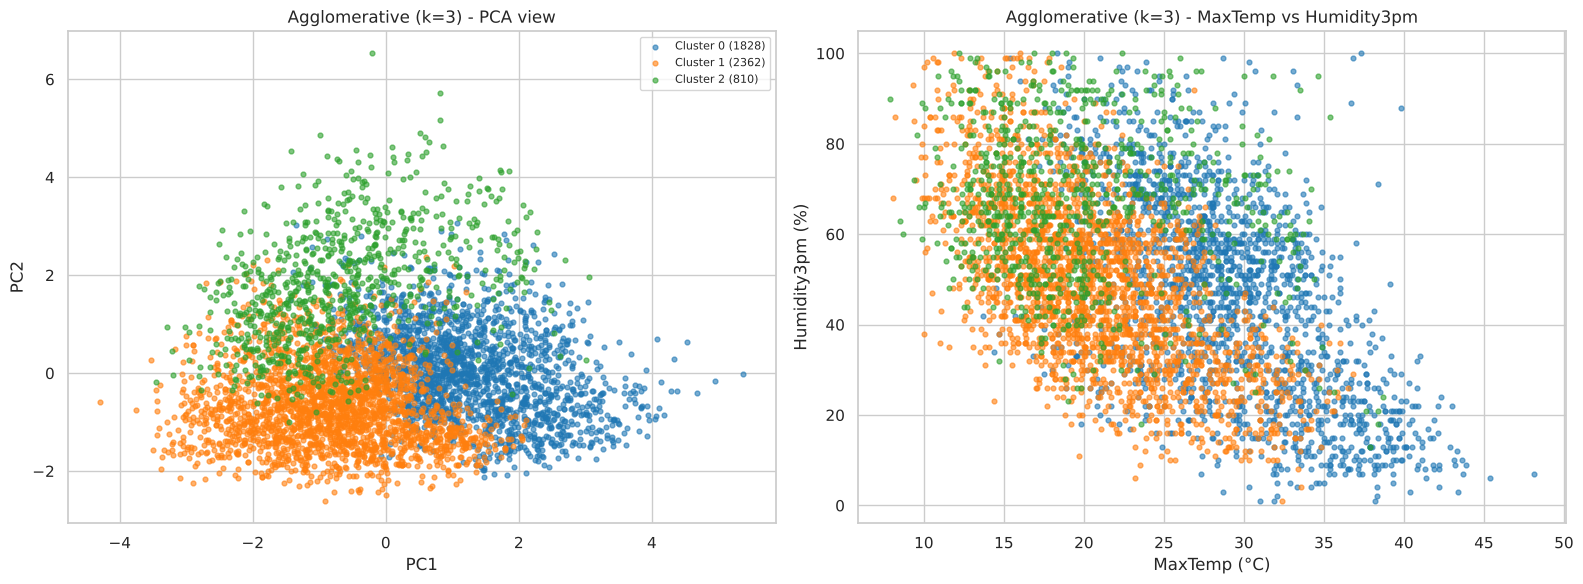

In [14]:
hc = AgglomerativeClustering(n_clusters=best_hc_k, linkage="ward").fit(X)
hc_labels = hc.labels_
print("Hierarchical cluster sizes:", dict(pd.Series(hc_labels).value_counts().sort_index()))
plot_clusters(hc_labels, f"Agglomerative (k={best_hc_k})", "07_hierarchical_clusters.png")

## 8. Algorithm 3 – DBSCAN
DBSCAN groups points that lie in dense regions and marks isolated points as **noise** (label −1). It needs two settings:
* `eps` – neighbourhood radius, `min_samples` – minimum points needed for a dense core.

We (1) draw a **k-distance graph** as a guide, (2) test a grid of `eps` and `min_samples`, and (3) pick the setting with the best silhouette score (computed on non-noise points) among settings that give 2–10 clusters and at most 15% noise.

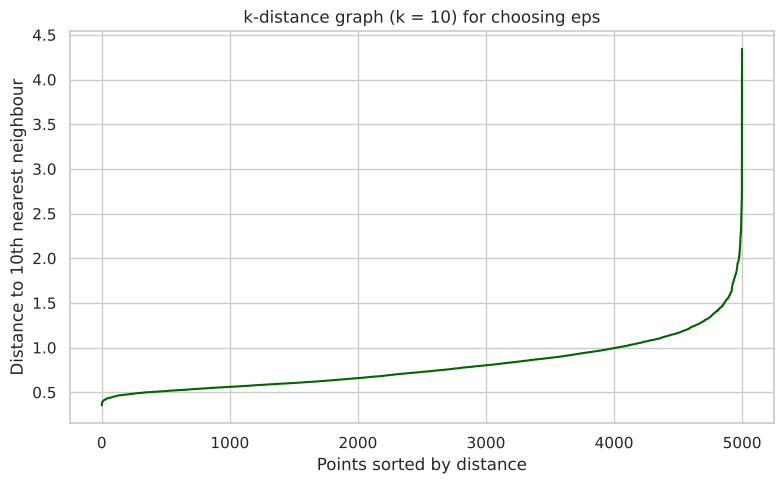

In [15]:
nn = NearestNeighbors(n_neighbors=10).fit(X)
dist, _ = nn.kneighbors(X)
kdist = np.sort(dist[:, -1])
plt.figure(figsize=(8, 5))
plt.plot(kdist, color="darkgreen")
plt.title("k-distance graph (k = 10) for choosing eps")
plt.xlabel("Points sorted by distance"); plt.ylabel("Distance to 10th nearest neighbour")
save_fig("08_dbscan_kdistance.png")

In [16]:
rows = []
for eps in np.round(np.arange(0.3, 2.01, 0.1), 2):
    for ms in [5, 10, 15, 20, 30]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        sil = db = np.nan
        mask = lab != -1
        if n_clusters >= 2 and mask.sum() > n_clusters:
            sil = silhouette_score(X[mask], lab[mask]); db = davies_bouldin_score(X[mask], lab[mask])
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_clusters, "noise": n_noise,
                     "noise_percent": round(100*n_noise/len(X), 2), "silhouette": sil, "davies_bouldin": db})
db_grid = pd.DataFrame(rows)

valid = db_grid[(db_grid.clusters >= 2) & (db_grid.clusters <= 10) & (db_grid.noise_percent <= 15)].dropna(subset=["silhouette"])
print("Number of valid DBSCAN settings:", len(valid))
display(valid.sort_values("silhouette", ascending=False).head(10).round(4))
best = valid.sort_values("silhouette", ascending=False).iloc[0]
best_eps, best_ms = float(best["eps"]), int(best["min_samples"])
print(f"Selected DBSCAN parameters: eps = {best_eps}, min_samples = {best_ms}")

Number of valid DBSCAN settings: 5


,eps,min_samples,clusters,noise,noise_percent,silhouette,davies_bouldin
45,1.2,5,2,85,1.70,0.3102,0.7958
30,0.9,5,2,414,8.28,0.2558,0.7392
35,1.0,5,3,250,5.00,0.2522,0.6260
31,0.9,10,2,739,14.78,0.2079,0.8462
25,0.8,5,10,747,14.94,0.0411,0.8404


Selected DBSCAN parameters: eps = 1.2, min_samples = 5


DBSCAN clusters found: 2 | noise points: 85 (1.70%)
Cluster sizes (-1 = noise): {-1: np.int64(85), 0: np.int64(4906), 1: np.int64(9)}


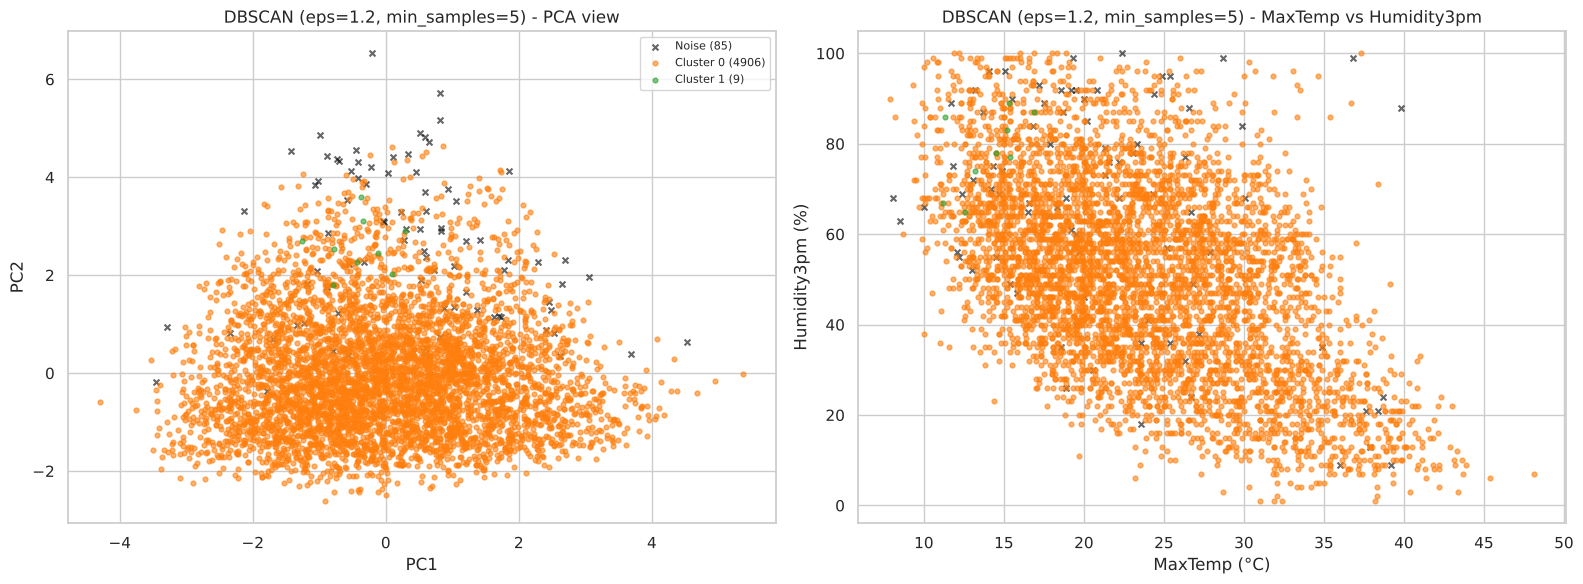

In [17]:
dbscan = DBSCAN(eps=best_eps, min_samples=best_ms).fit(X)
db_labels = dbscan.labels_
db_n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
db_noise = int((db_labels == -1).sum())
print("DBSCAN clusters found:", db_n_clusters, "| noise points:", db_noise, f"({100*db_noise/len(X):.2f}%)")
print("Cluster sizes (-1 = noise):", dict(pd.Series(db_labels).value_counts().sort_index()))
plot_clusters(db_labels, f"DBSCAN (eps={best_eps}, min_samples={best_ms})", "09_dbscan_clusters.png")

## 9. Evaluation and algorithm comparison
* **Silhouette Score** (−1 to 1, higher = better separated clusters)
* **Davies-Bouldin Index** (≥ 0, lower = better)
* **Number of clusters** and **DBSCAN noise count**

For DBSCAN the two scores are computed on non-noise points only (they cannot be computed for noise), so its scores are slightly favourable; this is stated in the report.

,Algorithm,Clusters,Noise Points,Silhouette,Davies-Bouldin
0,K-Means,3,0,0.2486,1.3553
1,Agglomerative (Ward),3,0,0.1919,1.5797
2,DBSCAN,2,85,0.3102,0.7958


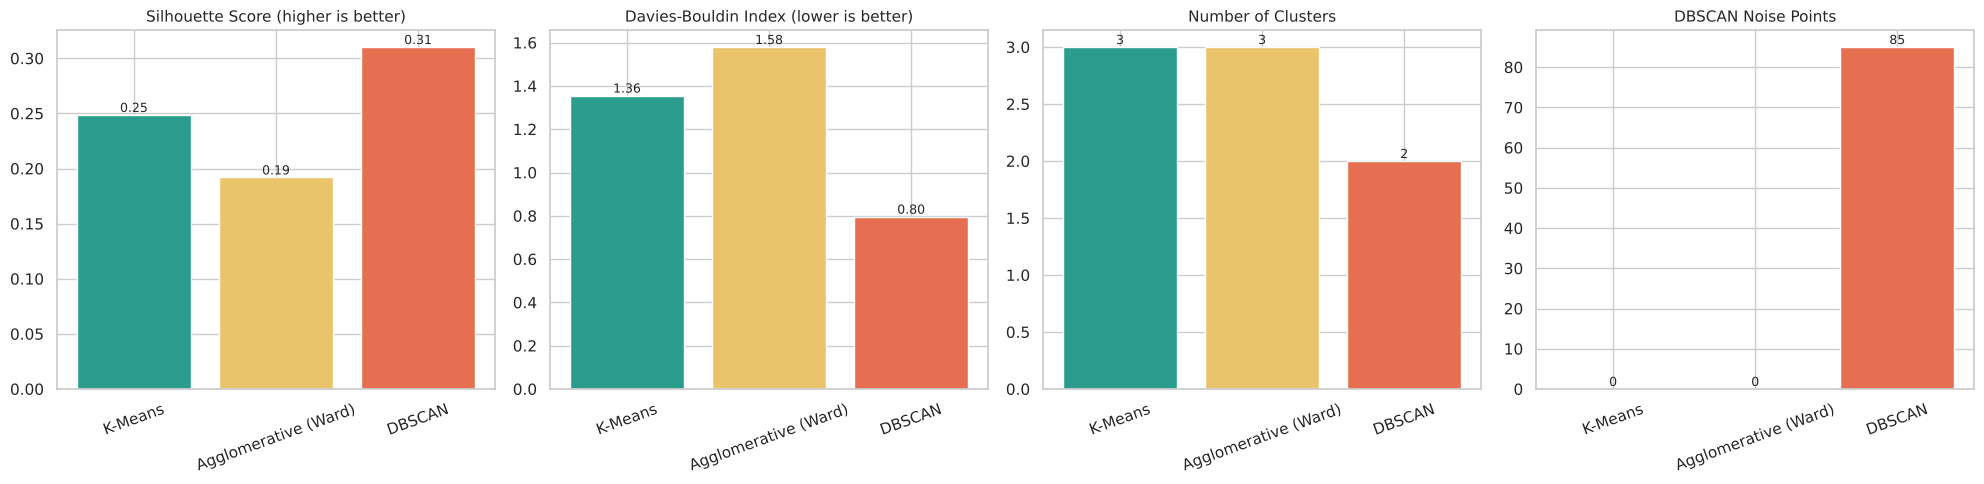

In [18]:
mask = db_labels != -1
results = pd.DataFrame([
    {"Algorithm": "K-Means", "Clusters": best_k, "Noise Points": 0,
     "Silhouette": silhouette_score(X, km_labels), "Davies-Bouldin": davies_bouldin_score(X, km_labels)},
    {"Algorithm": "Agglomerative (Ward)", "Clusters": best_hc_k, "Noise Points": 0,
     "Silhouette": silhouette_score(X, hc_labels), "Davies-Bouldin": davies_bouldin_score(X, hc_labels)},
    {"Algorithm": "DBSCAN", "Clusters": db_n_clusters, "Noise Points": db_noise,
     "Silhouette": silhouette_score(X[mask], db_labels[mask]) if db_n_clusters >= 2 else np.nan,
     "Davies-Bouldin": davies_bouldin_score(X[mask], db_labels[mask]) if db_n_clusters >= 2 else np.nan},
])
display(results.round(4))

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
cols = ["#2a9d8f", "#e9c46a", "#e76f51"]
for a, (metric, ttl) in zip(ax, [("Silhouette", "Silhouette Score (higher is better)"), ("Davies-Bouldin", "Davies-Bouldin Index (lower is better)"),
                                  ("Clusters", "Number of Clusters"), ("Noise Points", "DBSCAN Noise Points")]):
    bars = a.bar(results["Algorithm"], results[metric], color=cols)
    a.set_title(ttl, fontsize=11); a.tick_params(axis="x", rotation=20)
    for b, v in zip(bars, results[metric]):
        a.text(b.get_x()+b.get_width()/2, b.get_height(), f"{v:.2f}" if metric in ("Silhouette","Davies-Bouldin") else f"{int(v)}", ha="center", va="bottom", fontsize=9)
save_fig("10_algorithm_comparison.png")

## 10. Interpreting the natural weather groups
Now we look at the **average real weather values** of each cluster (original units) and give each cluster a descriptive name using simple rules:
* temperature from the cluster's mean `MaxTemp` compared with the 33rd / 66th percentiles of all days (Cool / Mild / Hot)
* humidity from mean `Humidity3pm` compared with 33rd / 66th percentiles (Dry / Moderate / Humid)
* a cluster is called **Rainy** if its mean rainfall is more than twice the overall mean

These names are only *interpretations after clustering*; they were never used as training labels.

In [19]:
t33, t66 = sample_orig["MaxTemp"].quantile([0.33, 0.66])
h33, h66 = sample_orig["Humidity3pm"].quantile([0.33, 0.66])
rain_mean = sample_orig["Rainfall"].mean()
print(f"Reference: MaxTemp 33%/66% = {t33:.1f}/{t66:.1f} °C | Humidity3pm 33%/66% = {h33:.1f}/{h66:.1f} % | mean rainfall = {rain_mean:.2f} mm")

def profile_and_name(labels):
    prof = sample_orig.assign(cluster=labels).groupby("cluster").agg(
        Days=("MaxTemp", "size"), MinTemp=("MinTemp", "mean"), MaxTemp=("MaxTemp", "mean"), Rainfall=("Rainfall", "mean"),
        Humidity3pm=("Humidity3pm", "mean"), WindSpeed3pm=("WindSpeed3pm", "mean"), Pressure3pm=("Pressure3pm", "mean"))
    names = {}
    for c, r in prof.iterrows():
        if c == -1:
            names[c] = "Noise / unusual days"; continue
        temp = "Cool" if r.MaxTemp < t33 else ("Hot" if r.MaxTemp > t66 else "Mild")
        hum = "Dry" if r.Humidity3pm < h33 else ("Humid" if r.Humidity3pm > h66 else "Moderate humidity")
        names[c] = f"Rainy ({temp}, {hum})" if r.Rainfall > 2 * rain_mean else f"{temp} / {hum}"
    prof["Interpretation"] = pd.Series(names)
    return prof

profiles = {"K-Means": profile_and_name(km_labels),
            "Agglomerative (Ward)": profile_and_name(hc_labels),
            "DBSCAN": profile_and_name(db_labels)}
for name, p in profiles.items():
    print("\n=== Cluster profiles:", name, "===")
    display(p.round(2))

Reference: MaxTemp 33%/66% = 19.7/26.3 °C | Humidity3pm 33%/66% = 42.0/60.0 % | mean rainfall = 2.51 mm

=== Cluster profiles: K-Means ===


,Days,MinTemp,MaxTemp,Rainfall,Humidity3pm,WindSpeed3pm,Pressure3pm,Interpretation
cluster,,,,,,,,
0,820,14.05,20.59,13.90,70.54,21.97,1011.93,"Rainy (Mild, Humid)"
1,2002,16.70,29.63,0.20,40.60,20.72,1011.42,Hot / Dry
2,2178,7.93,19.02,0.36,53.47,16.28,1019.94,Cool / Moderate humidity



=== Cluster profiles: Agglomerative (Ward) ===


,Days,MinTemp,MaxTemp,Rainfall,Humidity3pm,WindSpeed3pm,Pressure3pm,Interpretation
cluster,,,,,,,,
0,1828,17.35,29.00,0.45,46.33,21.71,1010.97,Hot / Moderate humidity
1,2362,8.61,20.61,0.17,49.49,16.30,1018.87,Mild / Moderate humidity
2,810,12.56,19.68,13.99,66.63,20.68,1014.14,"Rainy (Cool, Humid)"



=== Cluster profiles: DBSCAN ===


,Days,MinTemp,MaxTemp,Rainfall,Humidity3pm,WindSpeed3pm,Pressure3pm,Interpretation
cluster,,,,,,,,
-1,85,13.26,21.37,29.50,65.21,32.58,1005.36,Noise / unusual days
0,4906,12.44,23.58,2.05,50.82,18.70,1015.41,Mild / Moderate humidity
1,9,8.87,13.96,2.07,78.44,45.89,1004.32,Cool / Humid


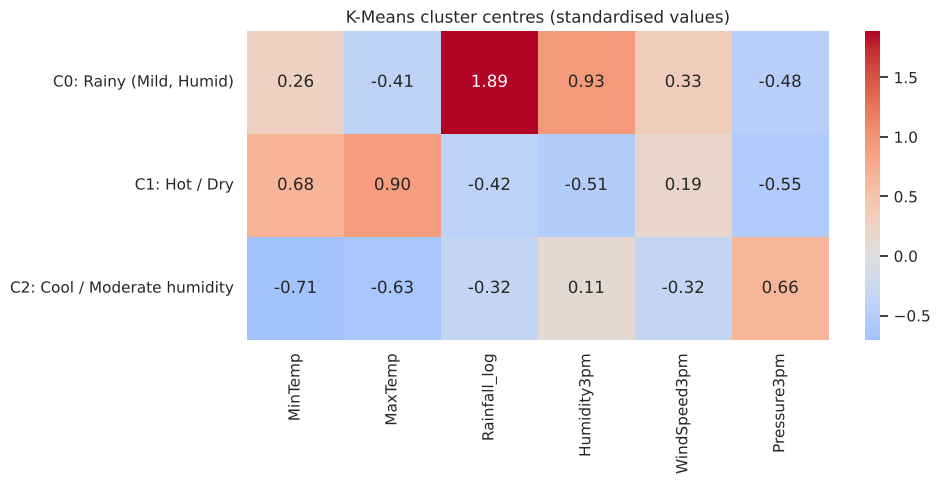

In [20]:
# Heatmap of standardised K-Means cluster centres: red = above average, blue = below average
centres = pd.DataFrame(kmeans.cluster_centers_, columns=X_model.columns)
centres.index = [f"C{i}: {profiles['K-Means'].loc[i,'Interpretation']}" for i in centres.index]
plt.figure(figsize=(10, 5))
sns.heatmap(centres, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("K-Means cluster centres (standardised values)")
save_fig("11_kmeans_cluster_profiles.png")

## 11. Save results for the project report

In [21]:
def clean(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    return str(o)

out = {
    "dataset": {"raw_rows": n_raw, "raw_cols": df_raw.shape[1], "duplicates": n_dup, "rows_after_dedup": len(df),
                "rows_before_dropna": n_before_na, "rows_after_dropna": len(df_clean), "sample_size": SAMPLE_SIZE,
                "missing_selected": missing_feat.to_dict(), "stations": int(df_raw["Location"].nunique()),
                "describe": summary.round(3).to_dict(), "corr": corr.round(3).to_dict(),
                "pca_var": pca.explained_variance_ratio_.tolist()},
    "kmeans_table": km_table.to_dict("records"), "best_k": best_k,
    "hier_table": hc_table.to_dict("records"), "best_hc_k": best_hc_k,
    "dbscan_eps": best_eps, "dbscan_min_samples": best_ms, "dbscan_valid_settings": int(len(valid)),
    "dbscan_top": valid.sort_values("silhouette", ascending=False).head(5).to_dict("records"),
    "results": results.to_dict("records"),
    "profiles": {k: v.reset_index().to_dict("records") for k, v in profiles.items()},
    "reference": {"t33": t33, "t66": t66, "h33": h33, "h66": h66, "rain_mean": rain_mean},
}
with open("results.json", "w") as f: json.dump(out, f, default=clean, indent=1)

# Local copy of the cleaned feature table (kept in the Colab/Jupyter session; the original data belong to the Bureau of Meteorology)
df_clean.to_csv("dataset_cleaned_features.csv", index=False)
print("Saved results.json and", len(os.listdir(GRAPH_DIR)), "graphs in", GRAPH_DIR)

Saved results.json and 11 graphs in output_graphs


## 12. Conclusion
* All three algorithms were applied to the same 5,000-day sample of real Bureau of Meteorology observations, with standardised features and a log-transformed rainfall.
* The comparison table above shows the actual Silhouette and Davies-Bouldin values, the number of clusters and the DBSCAN noise count. Read the cluster-profile tables to see which weather type each cluster represents.
* Because this is unsupervised learning, there is no accuracy score. Cluster quality is judged by internal measures and by whether the clusters make meteorological sense.
* **Limitations:** results depend on feature choice, sampling and parameter settings; rows with missing values were removed; the data mix many Australian climates.